In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

DATA = "../data/"
CHARTS = "../charts/"
BLUE = "#2a6f97"
GREY = "#b8c4ce"

news = pd.read_pickle(DATA + "news_clean.pkl")
behaviors = pd.read_pickle(DATA + "behaviors_clean.pkl")
impressions = pd.read_pickle(DATA + "impressions_clean.pkl")

print(f"{len(news):,} articles | {len(behaviors):,} sessions | {len(impressions):,} articles shown")

51,282 articles | 156,965 sessions | 5,843,444 articles shown


In [2]:
article_stats = (impressions.groupby("news_id")["clicked"]
                 .agg(shown="size", clicks="sum")
                 .sort_values("clicks", ascending=False))

n_articles = len(article_stats)
total_clicks = article_stats["clicks"].sum()
top1_n = round(n_articles * 0.01)
top10_n = round(n_articles * 0.10)

top1_share = article_stats["clicks"].iloc[:top1_n].sum() / total_clicks
top10_share = article_stats["clicks"].iloc[:top10_n].sum() / total_clicks

print(f"Articles shown to readers: {n_articles:,}")
print(f"Top 1% ({top1_n:,} articles) receive {top1_share:.1%} of all clicks")
print(f"Top 10% ({top10_n:,} articles) receive {top10_share:.1%} of all clicks")
print(f"Remaining 90% receive {1 - top10_share:.1%} of all clicks")

Articles shown to readers: 20,288
Top 1% (203 articles) receive 51.7% of all clicks
Top 10% (2,029 articles) receive 93.5% of all clicks
Remaining 90% receive 6.5% of all clicks


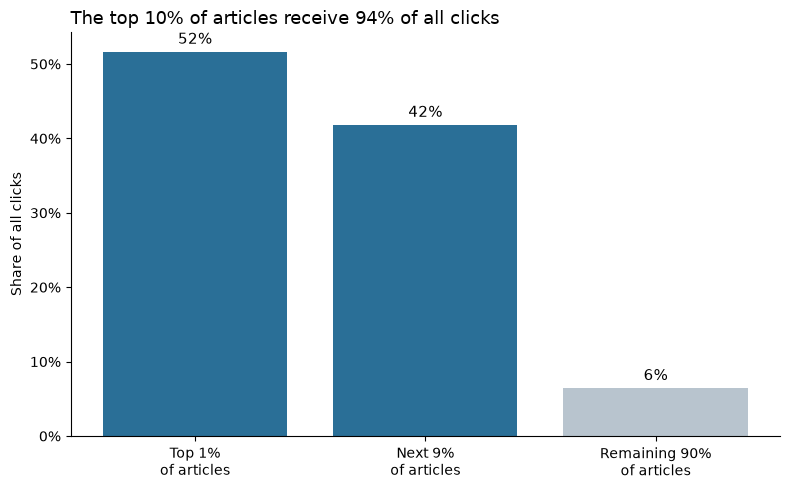

In [3]:
groups = pd.Series({
    "Top 1%\nof articles": top1_share,
    "Next 9%\nof articles": top10_share - top1_share,
    "Remaining 90%\nof articles": 1 - top10_share,
})

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(groups.index, groups.values, color=[BLUE, BLUE, GREY])
ax.bar_label(bars, labels=[f"{v:.0%}" for v in groups.values], padding=3, fontsize=11)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Share of all clicks")
ax.set_title(f"The top 10% of articles receive {top10_share:.0%} of all clicks",
             loc="left", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(CHARTS + "02_click_concentration.png", dpi=150)
plt.show()

In [4]:
published = news["news_id"].nunique()
shown = len(article_stats)
clicked_once = (article_stats["clicks"] > 0).sum()
never_clicked = shown - clicked_once

print(f"Articles in the archive: {published:,}")
print(f"Shown to readers this week: {shown:,}")
print(f"Clicked at least once: {clicked_once:,}")
print(f"Shown but never clicked: {never_clicked:,} ({never_clicked / shown:.1%})")

# Robustness check: articles shown at least 100 times
well_shown = article_stats[article_stats["shown"] >= 100]
zero_share = (well_shown["clicks"] == 0).mean()
print(f"\nArticles shown 100+ times: {len(well_shown):,}")
print(f"Of these, never clicked: {zero_share:.1%}")

Articles in the archive: 51,282
Shown to readers this week: 20,288
Clicked at least once: 7,713
Shown but never clicked: 12,575 (62.0%)

Articles shown 100+ times: 3,448
Of these, never clicked: 2.7%


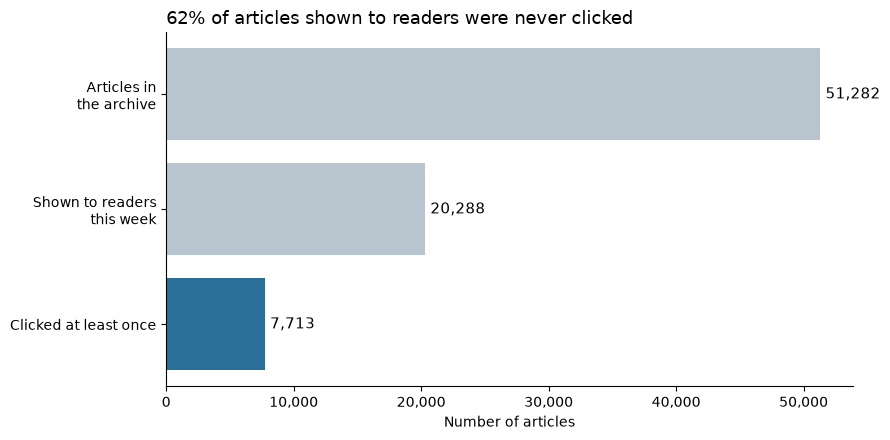

In [5]:
funnel = pd.Series({
    "Clicked at least once": clicked_once,
    "Shown to readers\nthis week": shown,
    "Articles in\nthe archive": published,
})

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(funnel.index, funnel.values, color=[BLUE, GREY, GREY])
ax.bar_label(bars, labels=[f"{v:,}" for v in funnel.values], padding=4, fontsize=11)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlabel("Number of articles")
ax.set_title(f"{never_clicked / shown:.0%} of articles shown to readers were never clicked",
             loc="left", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(CHARTS + "03_unseen_content.png", dpi=150)
plt.show()

In [6]:
imp_cat = impressions[["news_id", "clicked"]].merge(
    news[["news_id", "category"]], on="news_id", how="left")

cat = imp_cat.groupby("category")["clicked"].agg(shown="size", clicks="sum")
cat["click_rate"] = cat["clicks"] / cat["shown"]
cat["share_of_shown"] = cat["shown"] / cat["shown"].sum()
cat["share_of_clicks"] = cat["clicks"] / cat["clicks"].sum()
cat = cat[cat["shown"] >= 1000].sort_values("click_rate")

overall_rate = impressions["clicked"].mean()

cat.style.format({"shown": "{:,}", "clicks": "{:,}", "click_rate": "{:.1%}",
                  "share_of_shown": "{:.1%}", "share_of_clicks": "{:.1%}"})

,shown,clicks,click_rate,share_of_shown,share_of_clicks
category,,,,,
travel,"315,101","8,304",2.6%,5.4%,3.5%
autos,"271,426","7,428",2.7%,4.6%,3.1%
foodanddrink,"369,382","10,883",2.9%,6.3%,4.6%
entertainment,"349,930","10,530",3.0%,6.0%,4.5%
movies,"132,091","4,186",3.2%,2.3%,1.8%
health,"304,088","10,863",3.6%,5.2%,4.6%
finance,"564,671","20,597",3.6%,9.7%,8.7%
lifestyle,"655,440","26,584",4.1%,11.2%,11.2%
news,"1,591,038","69,408",4.4%,27.2%,29.4%


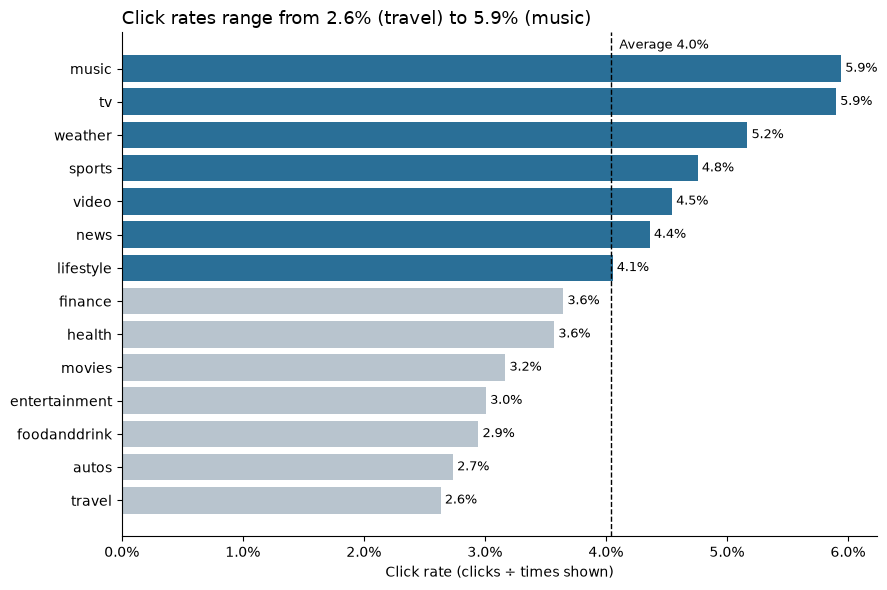

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
colors = [BLUE if r >= overall_rate else GREY for r in cat["click_rate"]]
bars = ax.barh(cat.index, cat["click_rate"], color=colors)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in cat["click_rate"]], padding=3, fontsize=9)
ax.axvline(overall_rate, color="black", linestyle="--", linewidth=1)
ax.text(overall_rate, len(cat) - 0.4, f"  Average {overall_rate:.1%}", fontsize=9)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Click rate (clicks ÷ times shown)")
low, high = cat.index[0], cat.index[-1]
ax.set_title(f"Click rates range from {cat['click_rate'].iloc[0]:.1%} ({low}) "
             f"to {cat['click_rate'].iloc[-1]:.1%} ({high})", loc="left", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(CHARTS + "04_click_rate_by_topic.png", dpi=150)
plt.show()

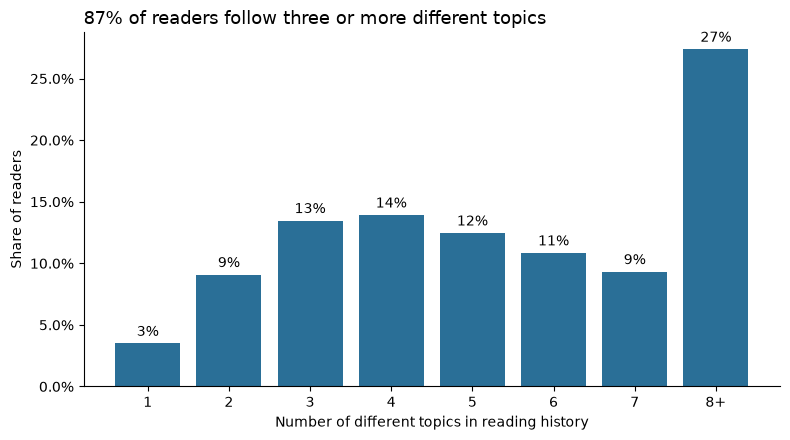

Readers with history analysed: 49,108


In [8]:
users = behaviors.drop_duplicates("user_id", keep="last")[["user_id", "history"]]

hist = (users.assign(news_id=users["history"].str.split())
        .explode("news_id")
        .dropna(subset=["news_id"])
        .merge(news[["news_id", "category"]], on="news_id", how="inner"))

breadth = hist.groupby("user_id")["category"].nunique()
share3 = (breadth >= 3).mean()

dist = breadth.clip(upper=8).value_counts(normalize=True).sort_index()
dist.index = [str(i) if i < 8 else "8+" for i in dist.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(dist.index, dist.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in dist.values], padding=3, fontsize=10)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Number of different topics in reading history")
ax.set_ylabel("Share of readers")
ax.set_title(f"{share3:.0%} of readers follow three or more different topics",
             loc="left", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(CHARTS + "05_reader_interests.png", dpi=150)
plt.show()

print(f"Readers with history analysed: {len(breadth):,}")

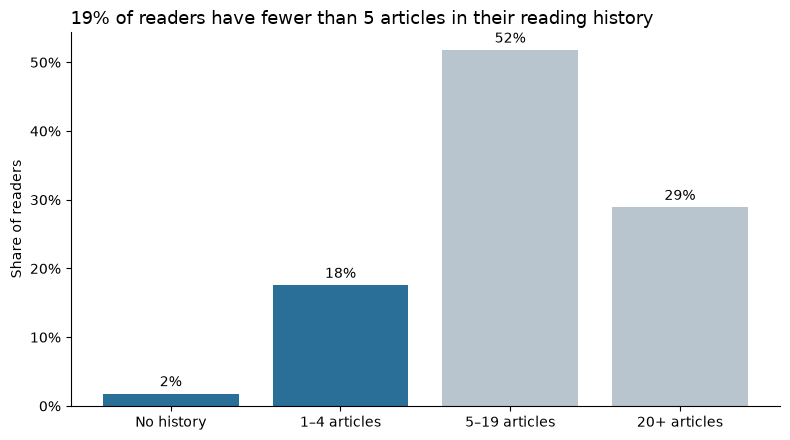

In [9]:
user_hist = behaviors.drop_duplicates("user_id", keep="last")["history_length"]

labels = ["No history", "1–4 articles", "5–19 articles", "20+ articles"]
groups = (pd.cut(user_hist, bins=[-1, 0, 4, 19, user_hist.max()], labels=labels)
          .value_counts(normalize=True).reindex(labels))
light = (user_hist < 5).mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(groups.index, groups.values, color=[BLUE, BLUE, GREY, GREY])
ax.bar_label(bars, labels=[f"{v:.0%}" for v in groups.values], padding=3, fontsize=10)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Share of readers")
ax.set_title(f"{light:.0%} of readers have fewer than 5 articles in their reading history",
             loc="left", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(CHARTS + "06_light_readers.png", dpi=150)
plt.show()

In [10]:
findings = pd.DataFrame({
    "Finding": [
        "Share of clicks going to the top 10% of articles",
        "Articles shown to readers but never clicked",
        "Of articles shown 100+ times, never clicked",
        "Overall click rate",
        f"Highest click rate topic ({high})",
        f"Lowest click rate topic ({low})",
        "Readers following 3+ topics",
        "Readers with fewer than 5 articles of history",
    ],
    "Value": [
        f"{top10_share:.0%}",
        f"{never_clicked / shown:.0%}",
        f"{zero_share:.0%}",
        f"{overall_rate:.1%}",
        f"{cat['click_rate'].iloc[-1]:.1%}",
        f"{cat['click_rate'].iloc[0]:.1%}",
        f"{share3:.0%}",
        f"{light:.0%}",
    ],
})
findings

,Finding,Value
0,Share of clicks going to the top 10% of articles,94%
1,Articles shown to readers but never clicked,62%
2,"Of articles shown 100+ times, never clicked",3%
3,Overall click rate,4.0%
4,Highest click rate topic (music),5.9%
5,Lowest click rate topic (travel),2.6%
6,Readers following 3+ topics,87%
7,Readers with fewer than 5 articles of history,19%
